In [1]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection
from mpl_toolkits.mplot3d import proj3d
import seaborn as sns


# Ensure scikit-bio is installed: pip install scikit-bio
from skbio.stats.composition import clr, clr_inv, ilr

import pickle

from pathlib import Path

In [2]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [ ]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = '#D27720'
ILR =  '#038C7F'

# Figure 1

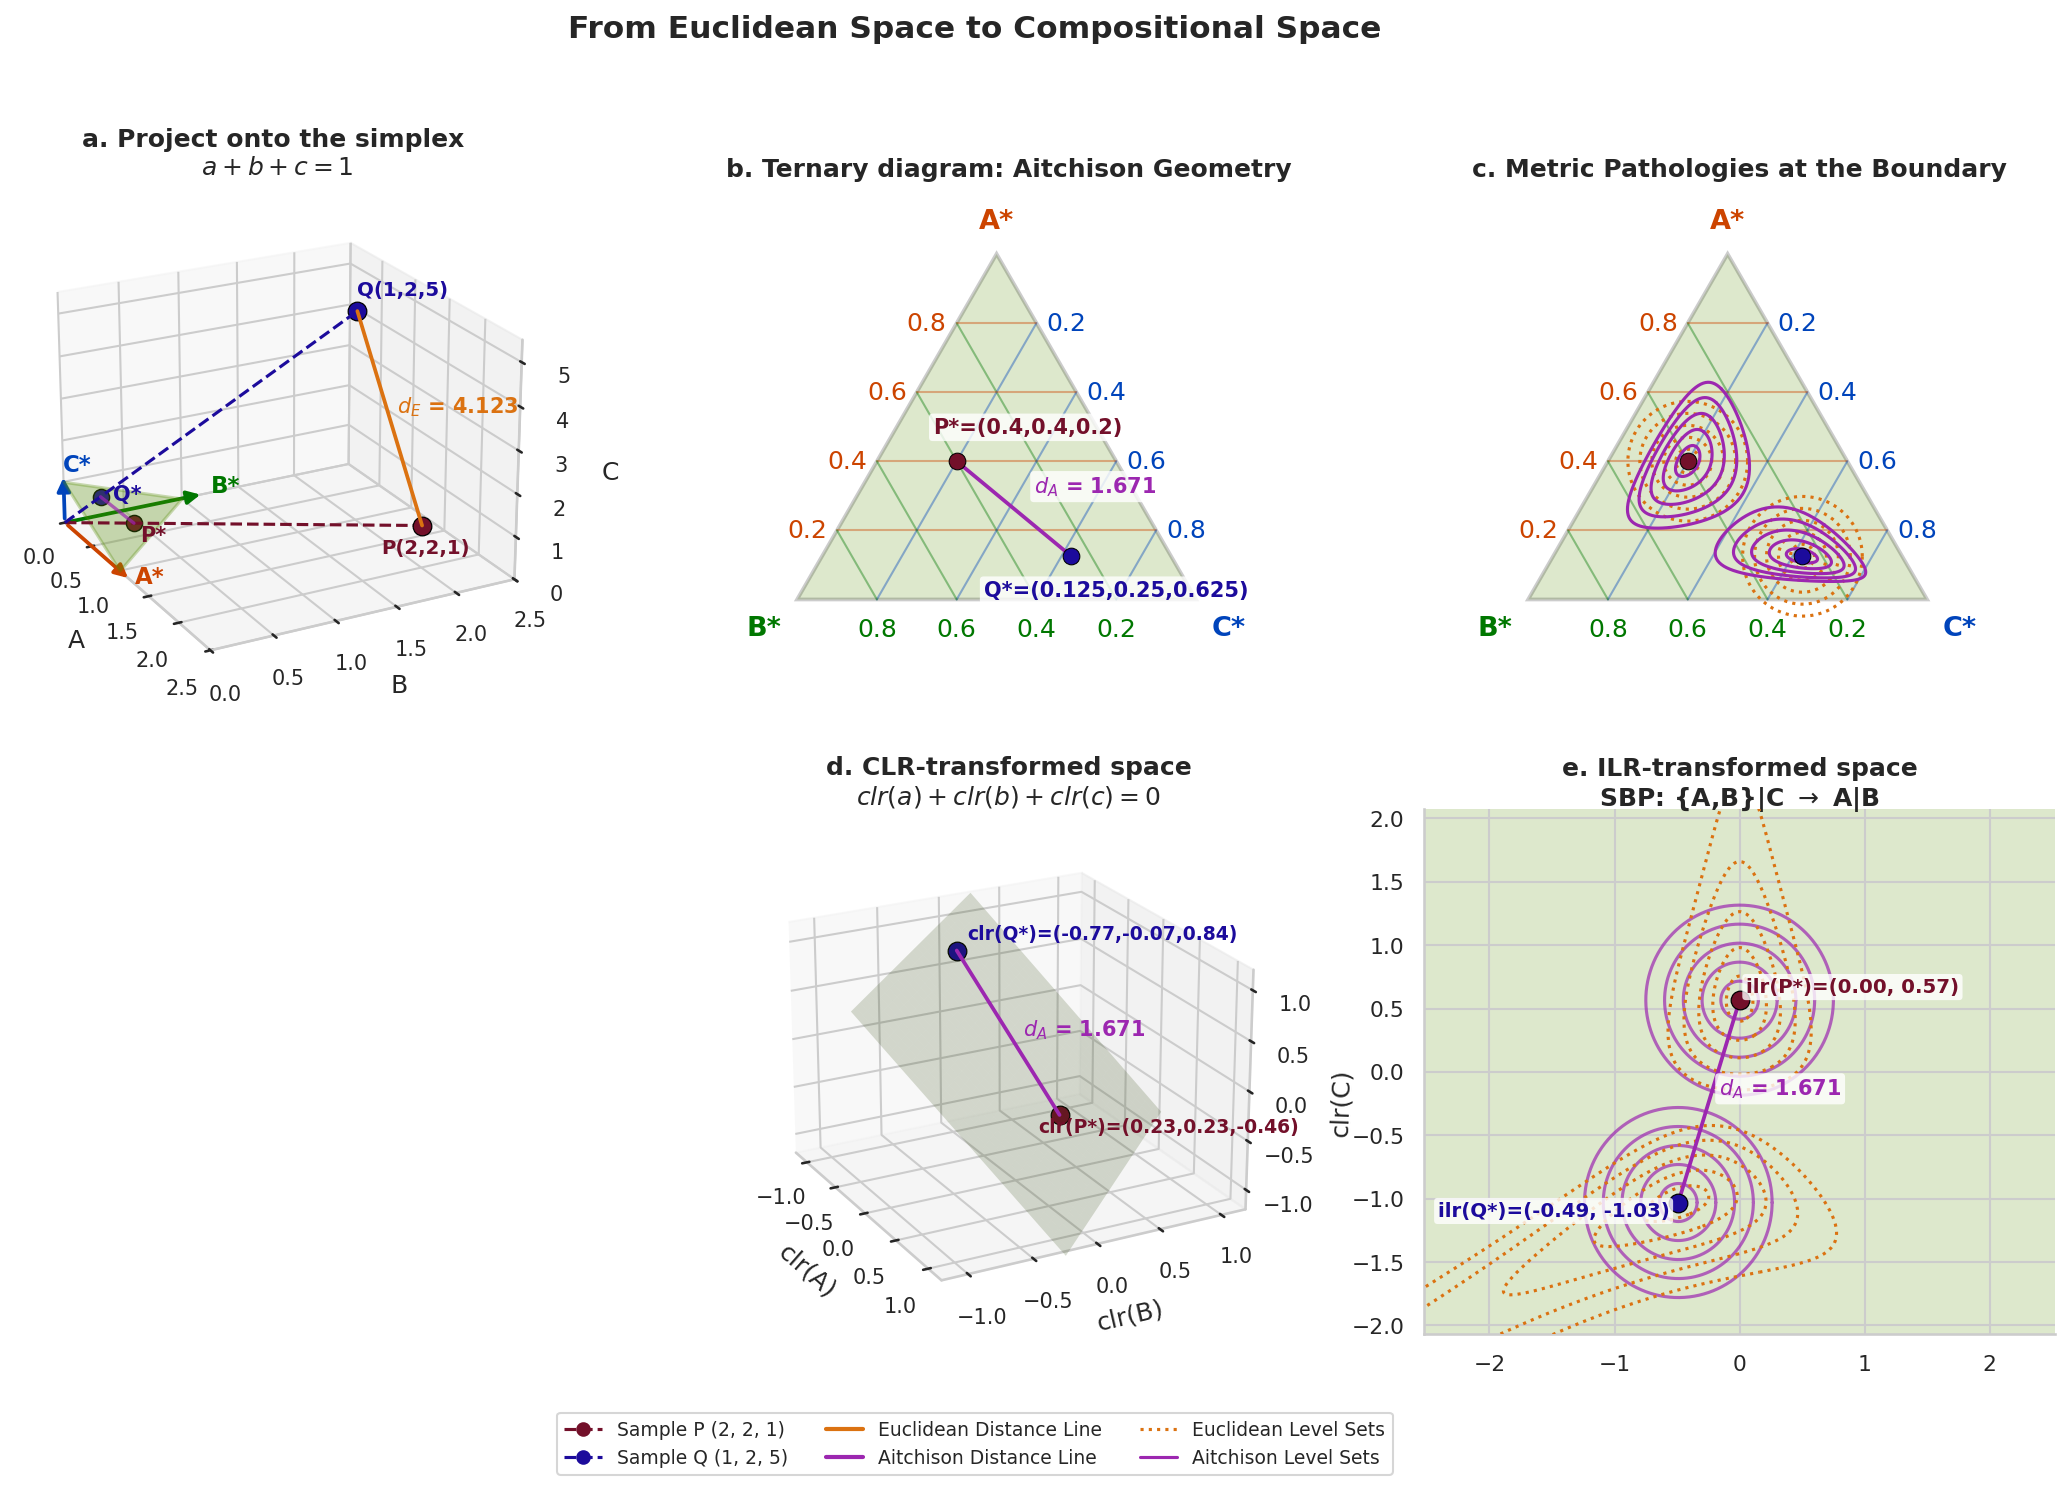

In [4]:
sns.set_theme(style='whitegrid', font_scale=0.95)

# ── 3D Arrow Helper ───────────────────────────────────────────────────────────
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return min(zs)

# ── helper functions ─────────────────────────────────────────────────────────
def _clr_local(v):
    v = np.asarray(v, float)
    return np.log(v) - np.mean(np.log(v))

def draw_point_box(ax, x, y, z, color, lw=0.7, edge_alpha=0.45, face_alpha=0.07):
    edges = [
        [(x,0,0),(x,y,0)], [(0,y,0),(x,y,0)], [(0,0,z),(x,0,z)], [(0,0,z),(0,y,z)],
        [(x,0,z),(x,y,z)], [(0,y,z),(x,y,z)], [(x,0,0),(x,0,z)], [(0,y,0),(0,y,z)],
        [(x,y,0),(x,y,z)],
    ]
    for (x0,y0,z0),(x1,y1,z1) in edges:
        ax.plot([x0,x1],[y0,y1],[z0,z1], color=color, lw=lw, alpha=edge_alpha, ls=':', zorder=2)
    faces = [
        [(0,0,0),(x,0,0),(x,y,0),(0,y,0)], [(0,0,z),(x,0,z),(x,y,z),(0,y,z)],
        [(0,y,0),(x,y,0),(x,y,z),(0,y,z)], [(0,0,0),(x,0,0),(x,0,z),(0,0,z)],
        [(0,0,0),(0,y,0),(0,y,z),(0,0,z)], [(x,0,0),(x,y,0),(x,y,z),(x,0,z)],
    ]
    poly = Poly3DCollection(faces, alpha=face_alpha, facecolor=color, edgecolor='none', zorder=1)
    ax.add_collection3d(poly)

def get_clr_ring_ternary(center_comp, radius, n_points=100):
    t = np.linspace(0, 2*np.pi, n_points)
    v1 = np.array([1, -1, 0]) / np.sqrt(2)
    v2 = np.array([1, 1, -2]) / np.sqrt(6)
    center_clr = clr(center_comp)
    ring_points_clr = []
    for angle in t:
        p_clr = center_clr + radius * (np.cos(angle) * v1 + np.sin(angle) * v2)
        ring_points_clr.append(clr_inv(p_clr))
    return np.array(ring_points_clr)

# ── reusable style: white background so labels stay readable over lines/points ─
_LBL = dict(
    bbox=dict(boxstyle='round,pad=0.18', facecolor='white', alpha=0.80, edgecolor='none'),
    zorder=20
)

# ── data for all panels ──────────────────────────────────────────────────────
a, b, c = 2, 2, 1
q, r, s = 1, 2, 5
a_close, b_close, c_close = a/(a+b+c), b/(a+b+c), c/(a+b+c)
q_close, r_close, s_close = q/(q+r+s), r/(q+r+s), s/(q+r+s)

d_E = float(np.linalg.norm([a - q, b - r, c - s]))
d_A = float(np.linalg.norm(_clr_local([a, b, c]) - _clr_local([q, r, s])))

clr_P = _clr_local([a_close, b_close, c_close])
clr_Q = _clr_local([q_close, r_close, s_close])

ilr_P = ilr(np.array([[a_close, b_close, c_close]]))[0]
ilr_Q = ilr(np.array([[q_close, r_close, s_close]]))[0]

# Shared level-set radii (same across panels C, D, E)
radii_eucl = [0.03, 0.06, 0.09, 0.12, 0.15]
radii_clr  = [0.15, 0.3, 0.45, 0.6, 0.75]

# ── figure layout — wspace increased to keep panel E clear of panel D ─────────
fig = plt.figure(figsize=(18, 10), dpi=150, facecolor='white')
gs  = gridspec.GridSpec(2, 6, figure=fig, wspace=0.38, hspace=0.2)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL A — row 0, cols 0-1
# ═════════════════════════════════════════════════════════════════════════════
ax1 = fig.add_subplot(gs[0, 0:2], projection='3d')

V = np.array([[1,0,0],[0,1,0],[0,0,1]], float)
ax1.add_collection3d(Poly3DCollection([V.tolist()], alpha=0.30,
                                       facecolor=OLIVE, edgecolor=OLIVE, linewidths=1.5))

AX_MAX2 = 1.2; AX2_MAX1 = 5; AX2_MAX2 = 2
for xs, ys, zs, col, lbl, tp in [
    ([0, AX_MAX2], [0, 0],       [0, 0],       A_COLOR, 'A*', (AX_MAX2+0.06, 0, 0)),
    ([0, 0],       [0, AX_MAX2], [0, 0],       B_COLOR, 'B*', (0, AX_MAX2+0.06, 0)),
    ([0, 0],       [0, 0],       [0, AX_MAX2], C_COLOR, 'C*', (0, 0, AX_MAX2+0.06)),
]:
    arr = Arrow3D(xs, ys, zs, arrowstyle="-|>", mutation_scale=13, lw=1.8, color=col, zorder=3)
    ax1.add_artist(arr)
    ax1.text(*tp, lbl, fontsize=11, fontweight='bold', color=col)

ax1.plot([0, a],[0, b],[0, c], color=CRIMSON, lw=1.5, ls='--', zorder=5)
ax1.plot([0, q],[0, r],[0, s], color=INDIGO,  lw=1.5, ls='--', zorder=5)
ax1.scatter([a],[b],[c], color=CRIMSON, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(a+0.1, b-0.4, c-0.3, f'P({a},{b},{c})', fontsize=9.5, fontweight='bold', color=CRIMSON, zorder=20)
ax1.scatter([q],[r],[s], color=INDIGO, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(q+0.02, r-0.02, s+0.4, f'Q({q},{r},{s})', fontsize=9.5, fontweight='bold', color=INDIGO, zorder=20)

ax1.plot([a_close,q_close],[b_close,r_close],[c_close,s_close], color=DIST_A, lw=1.6, zorder=6, alpha=0.7)
ax1.scatter([a_close],[b_close],[c_close], color=CRIMSON, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(a_close+0.06, b_close+0.02, c_close-0.4, 'P*', fontsize=10, fontweight='bold', color=CRIMSON, zorder=20)
ax1.plot([a,q],[b,r],[c,s], color=DIST_E, lw=1.8, zorder=6)
mx, my, mz = (a+q)/2, (b+r)/2, (c+s)/2
ax1.text(mx-0.04, my+0.09, mz+0.02, f'$d_E$ = {d_E:.3f}', fontsize=10, color=DIST_E, fontweight='bold', zorder=20)
ax1.scatter([q_close],[r_close],[s_close], color=INDIGO, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(q_close+0.05, r_close+0.08, s_close-0.08, 'Q*', fontsize=10, fontweight='bold', color=INDIGO, zorder=20)

ax1.set_xlim(0, AX2_MAX2+0.5); ax1.set_ylim(0, AX2_MAX2+0.5); ax1.set_zlim(0, AX2_MAX1+0.5)
ax1.set_xlabel('A', fontsize=12); ax1.set_ylabel('B', fontsize=12); ax1.set_zlabel('C', fontsize=12)
ax1.tick_params(labelsize=10)
ax1.set_title('a. Project onto the simplex \n$a + b + c = 1$', fontsize=12, fontweight='bold', pad=2)
ax1.view_init(elev=22, azim=-28)

# ═════════════════════════════════════════════════════════════════════════════
# COMMON TERNARY LOGIC
# ═════════════════════════════════════════════════════════════════════════════
TA = np.array([0.5, np.sqrt(3)/2])
TB = np.array([0.0, 0.0])
TC = np.array([1.0, 0.0])

def t2d(p_, q_, r_):
    return p_*TA + q_*TB + r_*TC

def t2d_inv(x, y):
    """Ternary 2D → (p, q, r) on the simplex."""
    p = 2 * y / np.sqrt(3)
    r = x - y / np.sqrt(3)
    q = 1 - p - r
    return np.array([p, q, r])

def draw_ternary_base(ax, title):
    ax.set_aspect('equal'); ax.set_axis_off()
    tri_patch = plt.Polygon([TA, TB, TC], facecolor=OLIVE, edgecolor='black', lw=1.8, alpha=0.2, zorder=1)
    ax.add_patch(tri_patch)
    for v in [0.2, 0.4, 0.6, 0.8]:
        p1, p2 = t2d(v, 1-v, 0), t2d(v, 0, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=A_COLOR, lw=1, alpha=0.4, zorder=2)
        p1, p2 = t2d(1-v, v, 0), t2d(0, v, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=B_COLOR, lw=1, alpha=0.4, zorder=2)
        p1, p2 = t2d(1-v, 0, v), t2d(0, 1-v, v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=C_COLOR, lw=1, alpha=0.4, zorder=2)
        pt_A = t2d(v, 1-v, 0)
        ax.text(pt_A[0]-0.025, pt_A[1], f'{v}', fontsize=12, color=A_COLOR, ha='right', va='center')
        pt_B = t2d(0, v, 1-v)
        ax.text(pt_B[0], pt_B[1]-0.045, f'{v}', fontsize=12, color=B_COLOR, ha='center', va='top')
        pt_C = t2d(v, 0, 1-v)
        ax.text(pt_C[0]+0.025, pt_C[1], f'{round(1-v,1)}', fontsize=12, color=C_COLOR, ha='left', va='center')
    ax.text(TA[0], TA[1]+0.05, 'A*', fontsize=13, fontweight='bold', color=A_COLOR, ha='center', va='bottom')
    ax.text(TB[0]-0.04, TB[1]-0.04, 'B*', fontsize=13, fontweight='bold', color=B_COLOR, ha='right', va='top')
    ax.text(TC[0]+0.04, TC[1]-0.04, 'C*', fontsize=13, fontweight='bold', color=C_COLOR, ha='left', va='top')
    ax.set_xlim(-0.26, 1.32); ax.set_ylim(-0.26, 1.05)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=2)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL B — row 0, cols 2-3
# ═════════════════════════════════════════════════════════════════════════════
ax2 = fig.add_subplot(gs[0, 2:4])
draw_ternary_base(ax2, 'b. Ternary diagram: Aitchison Geometry')

P2 = t2d(a_close, b_close, c_close)
Q2 = t2d(q_close, r_close, s_close)

ax2.plot(*P2, 'o', color=CRIMSON, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(P2[0]-0.06, P2[1]+0.07, f"P*=({a_close},{b_close},{c_close})",
         fontsize=10, fontweight='bold', color=CRIMSON, **_LBL)
ax2.plot(*Q2, 'o', color=INDIGO, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(Q2[0]-0.22, Q2[1]-0.10, f"Q*=({q_close},{r_close},{s_close})",
         fontsize=10, fontweight='bold', color=INDIGO, **_LBL)

# Aitchison distance line in ternary space
ax2.plot([P2[0], Q2[0]], [P2[1], Q2[1]], color=DIST_A, lw=1.8, zorder=6)
mx2 = (P2[0] + Q2[0]) / 2; my2 = (P2[1] + Q2[1]) / 2
ax2.text(mx2 + 0.05, my2 + 0.04, f'$d_A$ = {d_A:.3f}',
         fontsize=10, color=DIST_A, fontweight='bold', **_LBL)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL C — row 0, cols 4-5
# ═════════════════════════════════════════════════════════════════════════════
ax3 = fig.add_subplot(gs[0, 4:6])
draw_ternary_base(ax3, 'c. Metric Pathologies at the Boundary')

points_d  = [a_close, b_close, c_close], [q_close, r_close, s_close]
colors_d  = [CRIMSON, INDIGO]

for pi, p in enumerate(points_d):
    cx, cy = t2d(p[0], p[1], p[2])
    t_ang = np.linspace(0, 2*np.pi, 100)
    for ra in radii_eucl:
        ax3.plot(cx + ra*np.cos(t_ang), cy + ra*np.sin(t_ang),
                 color=DIST_E, lw=1.5, ls=':', zorder=4)
    for ra in radii_clr:
        ring = get_clr_ring_ternary(p, ra)
        x_clr = [t2d(tp[0], tp[1], tp[2])[0] for tp in ring]
        y_clr = [t2d(tp[0], tp[1], tp[2])[1] for tp in ring]
        x_clr.append(x_clr[0]); y_clr.append(y_clr[0])
        ax3.plot(x_clr, y_clr, color=DIST_A, lw=1.5, ls='-', zorder=5)
    ax3.plot([cx], [cy], marker='o', markersize=8, color=colors_d[pi],
             markeredgecolor='black', markeredgewidth=0.5, zorder=6)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL D — row 1, cols 2-3: CLR-transformed space  [bottom middle]
# ═════════════════════════════════════════════════════════════════════════════
ax_c = fig.add_subplot(gs[1, 2:4], projection='3d')

CLR_AX_MAX = 1.0

# Orthonormal basis of the CLR constraint plane (clr(A)+clr(B)+clr(C)=0)
_v1 = np.array([1, -1,  0]) / np.sqrt(2)
_v2 = np.array([1,  1, -2]) / np.sqrt(6)

# Constraint plane surface
_ss, _tt = np.linspace(-1.3, 1.3, 30), np.linspace(-1.3, 1.3, 30)
_SS, _TT = np.meshgrid(_ss, _tt)
_XP = _SS * _v1[0] + _TT * _v2[0]
_YP = _SS * _v1[1] + _TT * _v2[1]
_ZP = _SS * _v1[2] + _TT * _v2[2]
ax_c.plot_surface(_XP, _YP, _ZP, alpha=0.18, color=OLIVE, zorder=1, linewidth=0)

ax_c.scatter([clr_P[0]], [clr_P[1]], [clr_P[2]], color=CRIMSON, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_c.text(clr_P[0]+0.05, clr_P[1]-0.20, clr_P[2]-0.10,
          f'clr(P*)=({clr_P[0]:.2f},{clr_P[1]:.2f},{clr_P[2]:.2f})',
          fontsize=9, fontweight='bold', color=CRIMSON, zorder=20)

ax_c.scatter([clr_Q[0]], [clr_Q[1]], [clr_Q[2]], color=INDIGO, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_c.text(clr_Q[0]+0.05, clr_Q[1]+0.06, clr_Q[2]+0.12,
          f'clr(Q*)=({clr_Q[0]:.2f},{clr_Q[1]:.2f},{clr_Q[2]:.2f})',
          fontsize=9, fontweight='bold', color=INDIGO, zorder=20)

ax_c.plot([clr_P[0], clr_Q[0]], [clr_P[1], clr_Q[1]], [clr_P[2], clr_Q[2]],
          color=DIST_A, lw=1.8, zorder=6)
mx_c = (clr_P[0]+clr_Q[0])/2; my_c = (clr_P[1]+clr_Q[1])/2; mz_c = (clr_P[2]+clr_Q[2])/2
ax_c.text(mx_c+0.12, my_c+0.06, mz_c, f'$d_A$ = {d_A:.3f}',
          fontsize=10, color=DIST_A, fontweight='bold', zorder=20)

ax_c.set_xlim(-1.2, 1.2); ax_c.set_ylim(-1.2, 1.2); ax_c.set_zlim(-1.2, 1.2)
ax_c.set_xlabel('clr(A)', fontsize=12); ax_c.set_ylabel('clr(B)', fontsize=12); ax_c.set_zlabel('clr(C)', fontsize=12)
ax_c.tick_params(labelsize=10)
ax_c.set_title('d. CLR-transformed space\n$clr(a)+clr(b)+clr(c)=0$',
               fontsize=12, fontweight='bold', pad=2)
ax_c.view_init(elev=22, azim=-28)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL E — row 1, cols 4-5: ILR-transformed space  [bottom right]
# ═════════════════════════════════════════════════════════════════════════════
ax_e = fig.add_subplot(gs[1, 4:6])

ILR1_COLOR = '#7D3C98'
ILR2_COLOR = '#148F77'

ILR_PAD = 0.35
ILR_XLIM = max(abs(ilr_P[0]), abs(ilr_Q[0])) + ILR_PAD
ILR_YLIM = max(abs(ilr_P[1]), abs(ilr_Q[1])) + ILR_PAD

import matplotlib.colors as mcolors
_r, _g, _b, _ = mcolors.to_rgba(OLIVE)
ax_e.set_facecolor((_r, _g, _b, 0.20))

# Metric pathologies mirroring panel C
_t_ang = np.linspace(0, 2 * np.pi, 360)

for _p_s, _p_ilr_c in [([a_close, b_close, c_close], ilr_P),
                        ([q_close, r_close, s_close], ilr_Q)]:
    _cx, _cy = t2d(_p_s[0], _p_s[1], _p_s[2])

    for _ra in radii_clr:
        ax_e.plot(_p_ilr_c[0] + _ra * np.cos(_t_ang),
                  _p_ilr_c[1] + _ra * np.sin(_t_ang),
                  color=DIST_A, lw=1.5, ls='-', zorder=3, alpha=0.7)

    for _ra in radii_eucl:
        _xs_t = _cx + _ra * np.cos(_t_ang)
        _ys_t = _cy + _ra * np.sin(_t_ang)
        _seg_x, _seg_y = [], []
        for _xi, _yi in zip(_xs_t, _ys_t):
            _comp = t2d_inv(_xi, _yi)
            if np.all(_comp > 1e-10):
                _pt = ilr(_comp.reshape(1, -1))[0]
                _seg_x.append(_pt[0]); _seg_y.append(_pt[1])
            else:
                if len(_seg_x) > 1:
                    ax_e.plot(_seg_x, _seg_y, color=DIST_E, lw=1.5, ls=':', zorder=4)
                _seg_x, _seg_y = [], []
        if len(_seg_x) > 1:
            ax_e.plot(_seg_x, _seg_y, color=DIST_E, lw=1.5, ls=':', zorder=4)

# Scatter points
ax_e.scatter([ilr_P[0]], [ilr_P[1]], color=CRIMSON, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_e.text(ilr_P[0] + 0.05, ilr_P[1] + 0.06,
          f'ilr(P*)=({ilr_P[0]:.2f}, {ilr_P[1]:.2f})',
          fontsize=9.5, fontweight='bold', color=CRIMSON, **_LBL)

ax_e.scatter([ilr_Q[0]], [ilr_Q[1]], color=INDIGO, s=80, zorder=10,
             edgecolors='black', linewidths=0.6)
ax_e.text(ilr_Q[0] - 0.07, ilr_Q[1] - 0.11,
          f'ilr(Q*)=({ilr_Q[0]:.2f}, {ilr_Q[1]:.2f})',
          fontsize=9.5, fontweight='bold', color=INDIGO, ha='right', **_LBL)

# Distance line
ax_e.plot([ilr_P[0], ilr_Q[0]], [ilr_P[1], ilr_Q[1]], color=DIST_A, lw=1.8, zorder=7)
mx_e = (ilr_P[0] + ilr_Q[0]) / 2; my_e = (ilr_P[1] + ilr_Q[1]) / 2
ax_e.text(mx_e + 0.08, my_e + 0.05, f'$d_A$ = {d_A:.3f}',
          fontsize=10, color=DIST_A, fontweight='bold', **_LBL)

# Extra padding on all sides so panel E content stays clear of panel D boundary
ax_e.set_xlim(-ILR_XLIM * 3, ILR_XLIM * 3)
ax_e.set_ylim(-ILR_YLIM * 1.5, ILR_YLIM * 1.5)
for spine in ['top', 'right']:
    ax_e.spines[spine].set_visible(False)
ax_e.set_title('e. ILR-transformed space\nSBP: {A,B}|C $\\to$ A|B',
               fontsize=12, fontweight='bold', pad=2)

# ── Global Title and Legend ──────────────────────────────────────────────────
fig.suptitle('From Euclidean Space to Compositional Space', fontsize=15, fontweight='bold', y=0.99)

legend_elements = [
    Line2D([0],[0], color=CRIMSON, marker='o', ls='--', markersize=6, label=f'Sample P ({a}, {b}, {c})'),
    Line2D([0],[0], color=INDIGO,  marker='o', ls='--', markersize=6, label=f'Sample Q ({q}, {r}, {s})'),
    Line2D([0],[0], color=DIST_E,  lw=2, ls='-',  label='Euclidean Distance Line'),
    Line2D([0],[0], color=DIST_A,  lw=2, ls='-',  label='Aitchison Distance Line'),
    Line2D([0],[0], color=DIST_E,  lw=1.5, ls=':', label='Euclidean Level Sets'),
    Line2D([0],[0], color=DIST_A,  lw=1.5, ls='-', label='Aitchison Level Sets'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.01), fontsize=9, frameon=True, edgecolor='#cccccc')

for ax in [ax1, ax_c, ax2, ax3]:
    ax.title.set_y(1.5)

plt.savefig(PLOT_DIR / '1_cartesian_to_ternary_combined.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / '1_cartesian_to_ternary_combined.svg', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

# Figure ground true

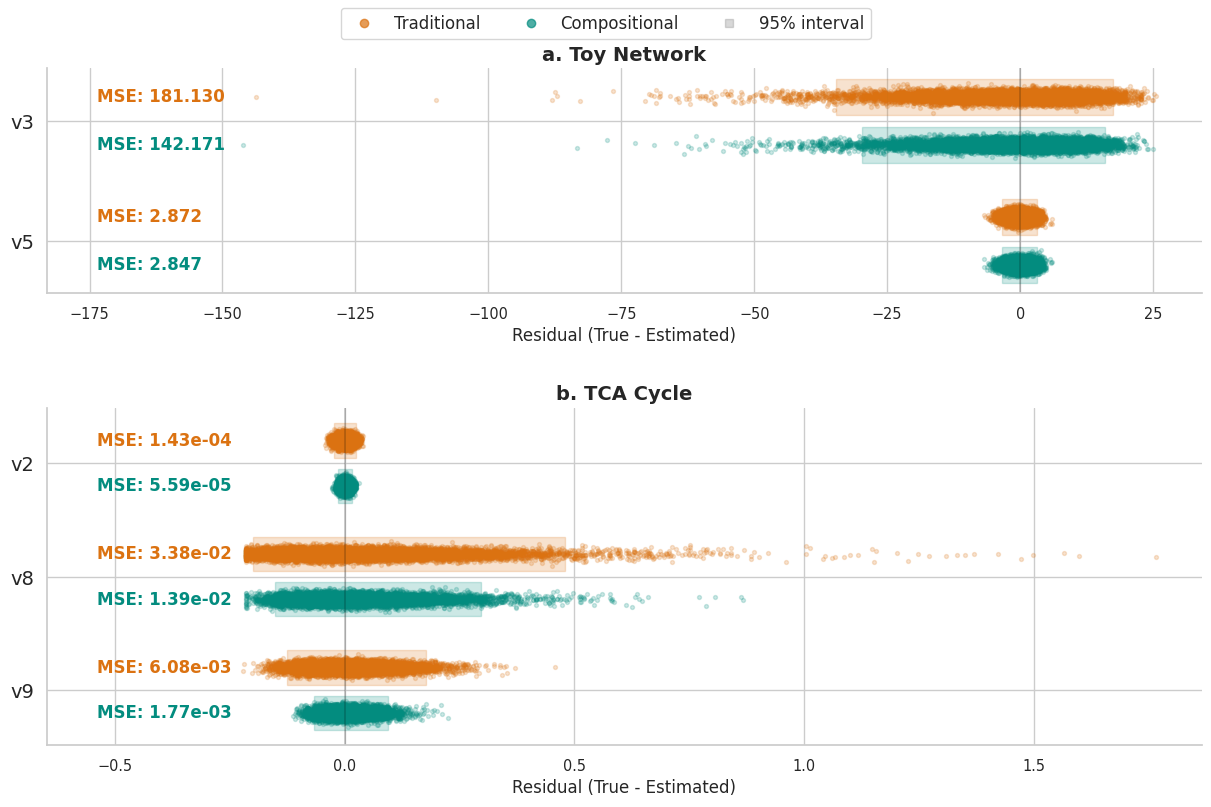

In [5]:
# --- 1. DATA LOADING & RESIDUALS ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined as in previous steps)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

res_trad_toy = (true_flux_toy[None, [2, 4]] - est_toy["trad"][:, [4, 5]])
res_comp_toy = (true_flux_toy[None, [2, 4]] - est_toy["ilr"][:, [4, 5]])
mse_trad_toy = (res_trad_toy ** 2).mean(axis=(0))
mse_comp_toy = (res_comp_toy ** 2).mean(axis=(0))

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]
mse_trad_tca = (res_trad_tca ** 2).mean(axis=(0))
mse_comp_tca = (res_comp_tca ** 2).mean(axis=(0))

# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.1}, layout="constrained")

def draw_scatter_with_95_interval(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (trad_data[i], pos + 0.2, TRAD, 'Traditional'),
            (comp_data[i], pos - 0.2, ILR, 'Compositional')
        ]
        
        for data, y_pos, color, label in data_pairs:
            # Calculate 95% Interval (2.5% to 97.5%)
            lower = np.percentile(data, 2.5)
            upper = np.percentile(data, 97.5)
            
            # Draw the 95% Sample Space Box
            rect = Rectangle((lower, y_pos - 0.15), upper - lower, 0.3, 
                             linewidth=1, edgecolor=color, facecolor=color, alpha=0.2)
            ax.add_patch(rect)
            
            # Draw Jittered Scatter Points
            jitter = np.random.normal(y_pos, 0.03, size=len(data))
            ax.scatter(data, jitter, color=color, s=8, alpha=0.20, label=label if i==0 else "")
            

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=14)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1.2)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

def mse_text(ax, mse_trad, mse_comp, labels, left_padding=0.15, fmt=".2g"):
    positions = np.arange(len(labels))[::-1]
    x_min, x_max = ax.get_xlim()
    
    # Calculate new x_min to create empty space on the left
    total_range = x_max - x_min
    new_x_min = x_min - (total_range * left_padding)
    ax.set_xlim(new_x_min, x_max)
    
    # Place text in the newly created space
    # text_x is slightly to the right of the new x_min
    text_x = new_x_min + (total_range * 0.05)
    
    for i, pos in enumerate(positions):
        ax.text(text_x, pos + 0.2, f"MSE: {mse_trad[i]:{fmt}}", 
                color=TRAD, fontsize=12, va='center', fontweight='bold')
        ax.text(text_x, pos - 0.2, f"MSE: {mse_comp[i]:{fmt}}", 
                color=ILR, fontsize=12, va='center', fontweight='bold')

# Render Toy Network
draw_scatter_with_95_interval(ax1, 
                              [res_trad_toy[:, 0], res_trad_toy[:, 1]], 
                              [res_comp_toy[:, 0], res_comp_toy[:, 1]], 
                              ["v3", "v5"])
mse_text(ax1, mse_trad_toy, mse_comp_toy, ["v3", "v5"], fmt=".3f")
ax1.set_title("a. Toy Network", fontweight='bold', fontsize=14)
ax1.set_xlabel("Residual (True - Estimated)", fontsize=12)

# Render TCA Cycle
draw_scatter_with_95_interval(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"],
                              )
# ax2.set_xlim(-0.25,1)
mse_text(ax2, 
        [mse_trad_tca[1], mse_trad_tca[0], mse_trad_tca[2]], 
        [mse_comp_tca[1], mse_comp_tca[0], mse_comp_tca[2]], 
        ["v2", "v8", "v9"],
        fmt = ".2e",
        )
ax2.set_title("b. TCA Cycle", fontweight='bold', fontsize=14)
ax2.set_xlabel("Residual (True - Estimated)", fontsize=12)

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color="grey", marker="s", linestyle="", markersize=6, alpha = 0.30),
]
fig.legend(custom_marker, ["Traditional", "Compositional", "95% interval"], fontsize=12, loc="outside upper center", ncols=3) #, bbox_to_anchor=(1.1,0.6)
plt.savefig(PLOT_DIR / 'flux_residuals.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / 'flux_residuals.svg', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [6]:
print("toy trad:", mse_trad_toy)
print("toy comp:", mse_comp_toy)

print("tca trad:", mse_trad_tca)
print("tca comp:", mse_comp_tca)

print(f"Presentage decrease: {((mse_trad_toy-mse_comp_toy)/mse_trad_toy)*100}")
print(f"Presentage decrease: {((mse_trad_tca-mse_comp_tca)/mse_trad_tca)*100}")
print(f"avarge improvement {np.mean(np.array([21.50901, 0.881893, 59.013947, 60.801823, 70.967606]))}")

toy trad: [181.12988     2.8719678]
toy comp: [142.17064   2.84664]
tca trad: [0.03382441 0.00014272 0.00608302]
tca comp: [1.3863293e-02 5.5945169e-05 1.7660466e-03]
Presentage decrease: [21.50901   0.881893]
Presentage decrease: [59.013947 60.801823 70.967606]
avarge improvement 42.634855800000004


# Figure mse diff 

In [7]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
free_fluxes_toy = np.load(RESULTS_DIR_TOY / "free_fluxes.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [4, 5]])
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [4, 5]])

mse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
mse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

In [8]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
free_fluxes_tca = jnp.load(RESULTS_DIR_TCA / "free_fluxes.npy", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

resid_trad_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["trad"][:, :, :])
resid_ilr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["ilr"][:, :, :])

mse_trad_tca = (resid_trad_tca ** 2).mean(axis=(0, 1))
mse_ilr_tca = (resid_ilr_tca ** 2).mean(axis=(0, 1))

diff_flux_tca= ((resid_trad_tca ** 2).mean(axis=1) - (resid_ilr_tca ** 2).mean(axis=1))

free_flux_numbers = jnp.array([8,2,9])

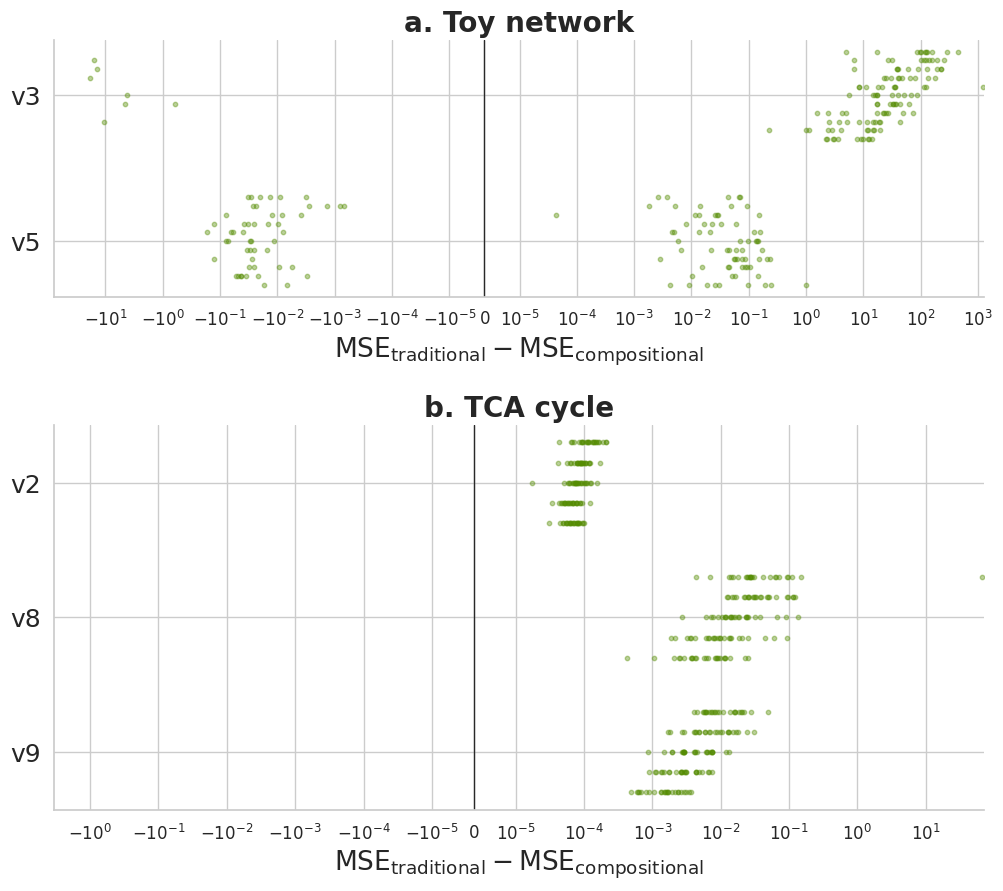

In [24]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.4})

def draw_scatter_ordered(ax, diff_data, flux_val, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        xmin = flux_val[i].min()
        xmax = flux_val[i].max()
        a, b = -0.3, 0.3
        flux_scaled = a + (flux_val[i] - xmin) * (b - a) / (xmax - xmin)
        data_pairs = [
            (diff_data[i], pos + flux_scaled)
        ]
        for data, y_pos in data_pairs:            
            ax.scatter(data, y_pos, color=OLIVE, s=10, alpha=0.40)
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=18)
    ax.axvline(0, color='black', linestyle='-', alpha=0.8, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_ordered(ax1, 
                    [diff_flux_toy[:, 0], diff_flux_toy[:, 1]], 
                    [free_fluxes_toy[:, 0], free_fluxes_toy[:, 1]], 
                    ["v3", "v5"])
ax1.set_title("a. Toy network", fontweight='bold', fontsize=20)
ax1.set_xlabel(r"$\mathrm{MSE_{traditional}} - \mathrm{MSE_{compositional}}$", fontsize=19)
ax1.set_xscale("symlog", linthresh=1e-5, linscale=0.55)
ax1.tick_params(axis="x", labelsize=12)

draw_scatter_ordered(ax2, 
                    [diff_flux_tca[:, 1], diff_flux_tca[:, 0], diff_flux_tca[:, 2]], 
                    [free_fluxes_tca[:, 1], free_fluxes_tca[:, 0], free_fluxes_tca[:, 2]], 
                    ["v2","v8", "v9"])
ax2.set_title("b. TCA cycle", fontweight='bold', fontsize=20)
ax2.set_xlabel(r"$\mathrm{MSE_{traditional}} - \mathrm{MSE_{compositional}}$", fontsize=19)
ax2.set_xscale("symlog", linthresh=1e-5, linscale=0.55)
ax2.tick_params(axis="x", labelsize=12)

plt.savefig(PLOT_DIR /'mse_difference.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

In [11]:
diff_flux_toy.mean(axis=0)

Array([5.9263008e+01, 3.0427998e-02], dtype=float32)

In [12]:
diff_flux_tca.mean(axis=0) # v8, v2, v9

Array([5.6684434e-01, 8.6684122e-05, 6.4712423e-03], dtype=float32)